# Importing Required Libraries

In [1]:
import pandas as pd 
import numpy as np 
import sys
import warnings
import itertools
warnings.filterwarnings("ignore")
from pandas.plotting import autocorrelation_plot
from statsmodels.graphics.tsaplots import plot_acf
from matplotlib import pyplot as plt
from pandas.plotting import lag_plot
import statsmodels.api as sm
import statsmodels.tsa.api as smt
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
%matplotlib inline
import datetime
import calendar
import seaborn as sns
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

Importing the Dataset

In [2]:
raw_data = pd.read_csv('superstoresales.csv')
raw_data['Order Date'] = pd.to_datetime(raw_data['Order Date'], format='%d/%m/%Y')
data = raw_data.set_index('Order Date')[['Sales']].resample('MS').sum().reset_index()
data.rename(columns={'Order Date': 'Month'}, inplace=True)
data['Month'] = data['Month'].dt.strftime('%Y-%m')
data.head()

,Month,Sales
0,2015-01,14205.707
1,2015-02,4519.892
2,2015-03,55205.797
3,2015-04,27906.855
4,2015-05,23644.303


Creating a date range

In [3]:
dates = pd.date_range(start='2015-01-01', freq='MS', periods=len(data))
dates[0:5]

DatetimeIndex(['2015-01-01', '2015-02-01', '2015-03-01', '2015-04-01',
               '2015-05-01'],
              dtype='datetime64[ns]', freq='MS')

In [4]:
data.set_index(dates,inplace=True)
data.drop('Month',axis=1,inplace=True)

# Modeling

In [5]:
train = (data[data.index < '2018-01-01'])
test = (data[data.index >= '2018-01-01'])

# Model 1: Auto Regressive

Auto regression model creates a lag data so that correlation of the created lag is high with the original data.
No.of lag can be defined manually  by seeing ACF plot. By default the algorithm shows the best lag.

In [6]:
lags=12
model = AutoReg(train,lags=lags)
model_fit = model.fit()

In [7]:
# Assuming you have already fitted the model (as shown in the previous code snippet)

# Get the number of lags considered statistically
lags_statistically = lags

# Get the coefficients (beta values) of the model
coefficients = model_fit.params

# Print the results
print(f"Lags considered statistically: {lags_statistically}")
print(f"Coefficients (beta values):\n{coefficients}")

Lags considered statistically: 12
Coefficients (beta values):
const       -45943.192185
Sales.L1         0.336820
Sales.L2         0.009989
Sales.L3         0.225438
Sales.L4        -0.036331
Sales.L5         0.247057
Sales.L6         0.118039
Sales.L7         0.127514
Sales.L8         0.114043
Sales.L9        -0.030018
Sales.L10        0.110879
Sales.L11        0.085419
Sales.L12        0.904466
dtype: float64


The no of best lag for this data is 12 and all the correlation of the lags with the original sales is listed

In [8]:
# Predicting the test values
predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)

In [9]:
print('The first test value in Sales :',test.values[1],'and its Predicted value : ',predictions.values[1])

The first test value in Sales : [19920.9974] and its Predicted value :  43639.26579998384


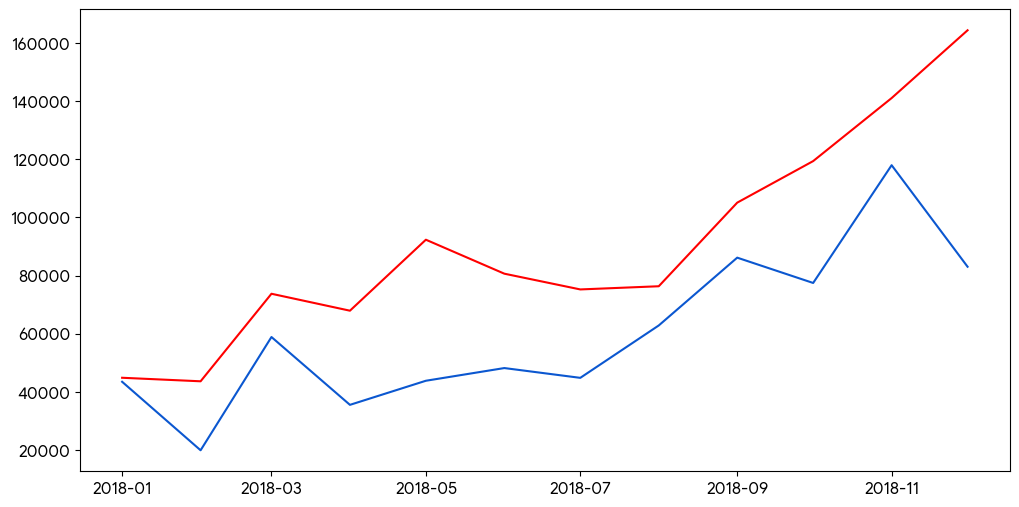

In [10]:
# plot results
plt.figure(figsize=(12,6))
plt.plot(test)
plt.plot(predictions, color='red')
plt.show()

In [11]:
# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test['Sales'], predictions))
rmse = round(rmse, 3)

In [12]:
# Mean Absolute Percentage Error
abs_error = np.abs(test['Sales']-predictions)
actual = test['Sales']
mape = np.round(np.mean(abs_error/actual),3)
resultsDf = pd.DataFrame({'Method':['Auto Regressive'], 'RMSE': [rmse]})
resultsDf
mape

0.583

In [13]:
# Storing results in a dataframe
resultsDf = pd.DataFrame({'Method':['Auto Regressive'], 'MAPE': [mape], 'RMSE': [rmse]})
resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
resultsDf

,Method,RMSE,MAPE
0,Auto Regressive,36056.661,0.583


# Model 2: Auto Regressive Integrated Moving Average(ARIMA)

The model involves specifying the order for the AR(p) and MA(q) model

Best ARIMA (1, 0) model - AIC:828.1443550739608
Order of AR part: 1
Coefficients: const     4.276347e+04
ar.L1     2.723111e-01
sigma2    4.760433e+08
dtype: float64


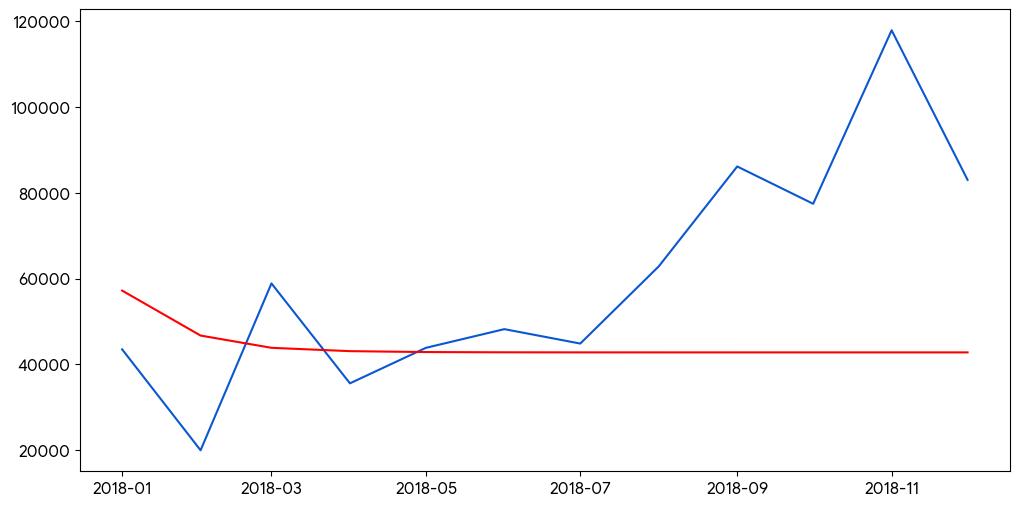

,Method,RMSE,MAPE
0,Auto Regressive,36056.661,0.583
0,Auto Regressive Moving average,31599.939,0.392


In [14]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

# Define the p and q parameters to take any value between 0 and 7
p = range(0, 7)
q = range(0,1)

# Generate all different combinations of p,q
pq = list(itertools.product(p,q))

best_aic = np.inf
best_pq = None
temp_model = None 

for param in pq: 
    try:
        temp_model = ARIMA(train, order=(param[0], 0, param[1]))
        results = temp_model.fit()
        if results.aic < best_aic:
            best_aic = results.aic
            best_pq = param
    except:
        continue

print("Best ARIMA {} model - AIC:{}".format(best_pq, best_aic))

# using the best parameter in the model
model = ARIMA(train, order=(best_pq[0], 0, best_pq[1]))
model_fit = model.fit()

# Print the order of the AR part of the model
print('Order of AR part: %s' % best_pq[0])

# Print the coefficients
print('Coefficients: %s' % model_fit.params)

predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1)

# plot results
plt.figure(figsize=(12,6))
plt.plot(test)
plt.plot(predictions, color='red')
plt.show()

# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test['Sales'], predictions))
rmse = round(rmse, 3)

# Mean Absolute Percentage Error
abs_error = np.abs(test['Sales']-predictions)
actual = test['Sales']
mape = np.round(np.mean(abs_error/actual),3)

# Storing results in a dataframe
tempResultsDf = pd.DataFrame({'Method':['Auto Regressive Moving average '], 'RMSE': [rmse],'MAPE': [mape] })
resultsDf = pd.concat([resultsDf, tempResultsDf])
resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
resultsDf

# Model 2: Seasonal Auto Regressive Integrated Moving Average(SARIMA)

It combines the ARIMA model with the ability to perform the same autoregression, differencing, and moving average modeling at the seasonal level. 

Best SARIMA (0, 1, 1) x (0, 1, 1, 12) model - AIC:199.5088859178159


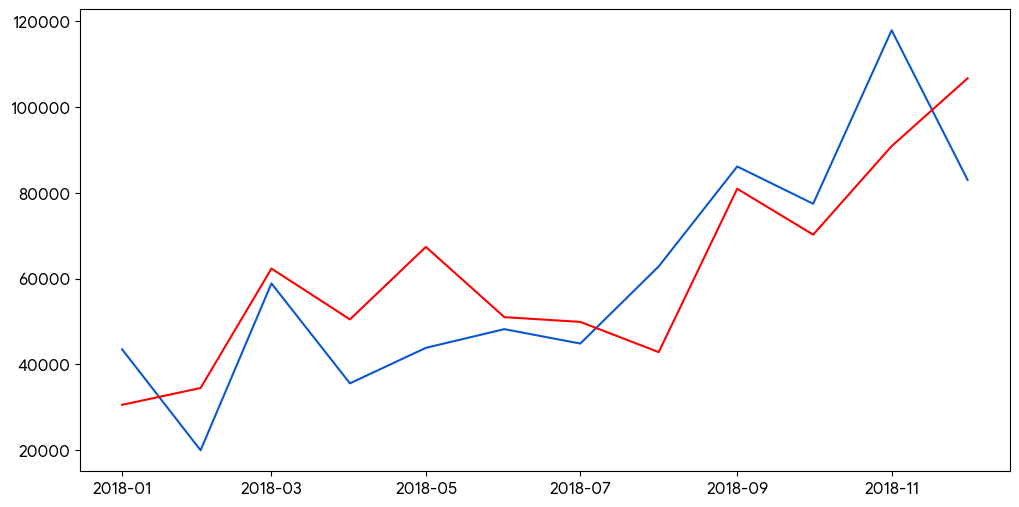

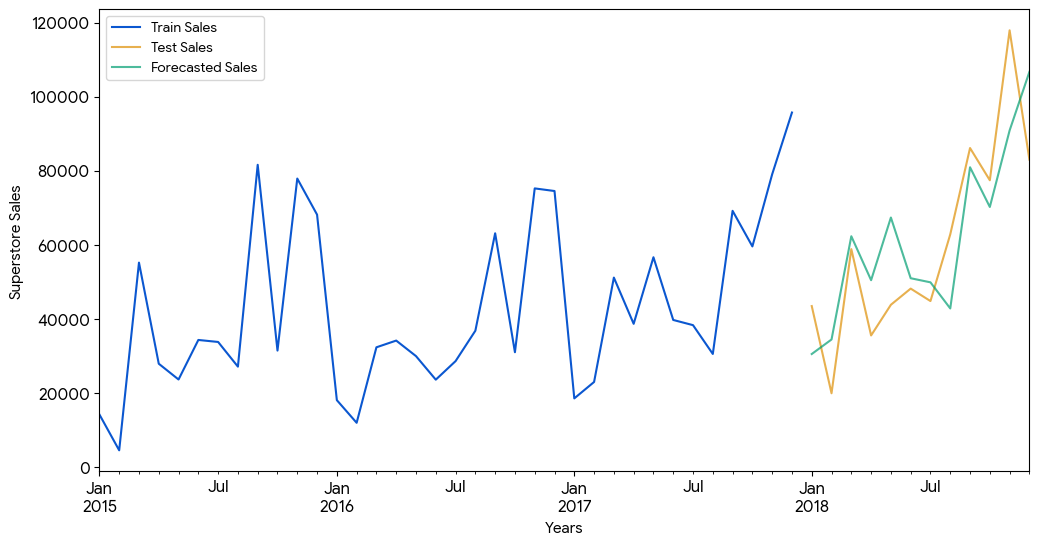

In [15]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error

# Define the p, d and q parameters to take any value between 0 and 2
p = d = q = range(0, 2)

# Generate all different combinations of p, d and q triplets
pdq = list(itertools.product(p, d, q))

# Generate all different combinations of seasonal p, q and q triplets
seasonal_pdq = [(x[0], x[1], x[2], 12) for x in list(itertools.product(p, d, q))]

best_aic = np.inf
best_pdq = None
best_seasonal_pdq = None
temp_model = None

for param in pdq:   
    for param_seasonal in seasonal_pdq: 
        try:
            temp_model = SARIMAX(train, order=param, seasonal_order=param_seasonal, enforce_invertibility=False, enforce_stationarity=False)
            results = temp_model.fit(disp=False)
            if results.aic < best_aic:
                best_aic = results.aic
                best_pdq = param
                best_seasonal_pdq = param_seasonal
        except:
            continue

print("Best SARIMA {} x {} model - AIC:{}".format(best_pdq, best_seasonal_pdq, best_aic))

# using the best parameter in the model
model = SARIMAX(train, order=best_pdq, seasonal_order=best_seasonal_pdq, enforce_invertibility=False, enforce_stationarity=False)
model_fit = model.fit()

predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)

# plot results
plt.figure(figsize=(12,6))
plt.plot(test)
plt.plot(predictions, color='red')
plt.show()

# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test['Sales'], predictions))
rmse = round(rmse, 3)

# Mean Absolute Percentage Error
abs_error = np.abs(test['Sales']-predictions)
actual = test['Sales']
mape = np.round(np.mean(abs_error/actual),3)

# Storing results in a dataframe
tempResultsDf = pd.DataFrame({'Method':['Seasonal Autoregressive Integrated Moving Average'], 'RMSE': [rmse],'MAPE': [mape] })
resultsDf = pd.concat([resultsDf, tempResultsDf])
resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
resultsDf.index = [i for i in range(len(resultsDf))]
resultsDf

# Plotting the train, test and forecasted sales
axis = train['Sales'].plot(label='Train Sales', figsize=(12, 6))
test['Sales'].plot(ax=axis, label='Test Sales', alpha=0.7)
predictions.plot(ax=axis, label='Forecasted Sales', alpha=0.7)
axis.set_xlabel('Years')
axis.set_ylabel('Superstore Sales')
plt.legend(loc='best')
plt.show()
plt.close()

In [16]:
# Storing results in a dataframe

print(resultsDf)

                                              Method       RMSE   MAPE
0                                    Auto Regressive  36056.661  0.583
1                    Auto Regressive Moving average   31599.939  0.392
2  Seasonal Autoregressive Integrated Moving Average  15742.153  0.267
